In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score,root_mean_squared_error,mean_absolute_error
import os
from tqdm import tqdm

In [9]:
wisconsin = pd.read_csv("D:\Machine Learning\Datasets\Cases\Wisconsin\BreastCancer.csv")
wisconsin

,Code,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
0,61634,5,4,3,1,2,2,2,3,1,Benign
1,63375,9,1,2,6,4,10,7,7,2,Malignant
2,76389,10,4,7,2,2,8,6,1,1,Malignant
3,95719,6,10,10,10,8,10,7,10,7,Malignant
4,128059,1,1,1,1,2,5,5,1,1,Benign
...,...,...,...,...,...,...,...,...,...,...,...
694,1369821,10,10,10,10,5,10,10,10,7,Malignant
695,1371026,5,10,10,10,4,10,5,6,3,Malignant
696,1371920,5,1,1,1,2,1,3,2,1,Benign
697,8233704,4,1,1,1,1,1,2,1,1,Benign


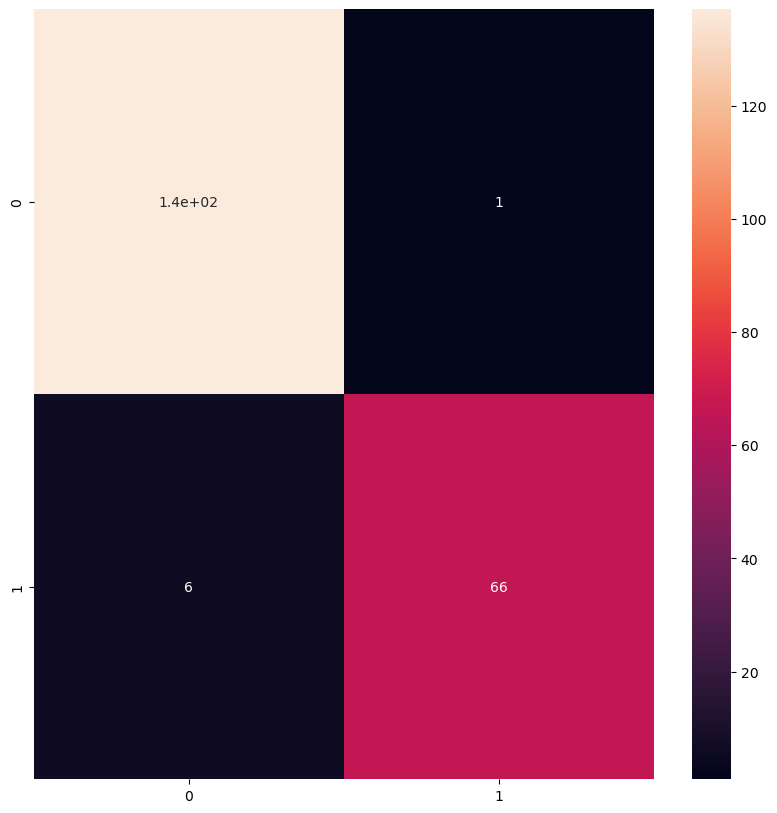

In [10]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
wisconsin['Class'] = le.fit_transform(wisconsin['Class'])

wisconsin.head()

X=wisconsin.drop(['Class','Code'],axis=1)
y=wisconsin['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=25,stratify=y)
#
#

lr=LogisticRegression()
lr.fit(X_train,y_train)
# lr.predict_proba(X_test)
lr.intercept_,lr.coef_

X_test.shape

y_pred_prob=lr.predict_proba(X_test)
y_pred_prob

X_test

y_test

lr.predict(X_test)

from sklearn.metrics import confusion_matrix
confusion_matrix(y_test,lr.predict(X_test))

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
sns.heatmap(confusion_matrix(y_test,lr.predict(X_test)),annot=True)
plt.show()

In [11]:
y_pred_prob

array([[9.98120767e-01, 1.87923285e-03],
       [9.98229749e-01, 1.77025092e-03],
       [1.96481629e-04, 9.99803518e-01],
       [9.82482033e-01, 1.75179672e-02],
       [9.94408267e-01, 5.59173308e-03],
       [5.51665724e-01, 4.48334276e-01],
       [2.05397996e-03, 9.97946020e-01],
       [9.76178351e-01, 2.38216491e-02],
       [9.98597104e-01, 1.40289575e-03],
       [9.96557412e-01, 3.44258849e-03],
       [9.99275706e-01, 7.24293521e-04],
       [9.98134279e-01, 1.86572114e-03],
       [5.46197681e-04, 9.99453802e-01],
       [9.89788038e-01, 1.02119620e-02],
       [9.89788038e-01, 1.02119620e-02],
       [9.98903064e-01, 1.09693596e-03],
       [1.16178478e-01, 8.83821522e-01],
       [9.98911740e-01, 1.08825963e-03],
       [9.98911740e-01, 1.08825963e-03],
       [9.90375598e-01, 9.62440163e-03],
       [9.96542540e-01, 3.45746032e-03],
       [7.31077129e-01, 2.68922871e-01],
       [4.51767821e-04, 9.99548232e-01],
       [4.26536006e-02, 9.57346399e-01],
       [9.958841

In [17]:
y_pred=lr.predict(X_test)

In [13]:
confusion_matrix(y_test,lr.predict(X_test))

array([[137,   1],
       [  6,  66]])

In [14]:
le.inverse_transform(wisconsin['Class'])

array(['Benign', 'Malignant', 'Malignant', 'Malignant', 'Benign',
       'Malignant', 'Malignant', 'Malignant', 'Malignant', 'Benign',
       'Benign', 'Benign', 'Benign', 'Malignant', 'Malignant', 'Benign',
       'Malignant', 'Malignant', 'Malignant', 'Malignant', 'Malignant',
       'Malignant', 'Malignant', 'Benign', 'Malignant', 'Benign',
       'Benign', 'Malignant', 'Benign', 'Benign', 'Malignant', 'Benign',
       'Benign', 'Malignant', 'Benign', 'Benign', 'Malignant', 'Benign',
       'Malignant', 'Benign', 'Benign', 'Benign', 'Benign', 'Benign',
       'Benign', 'Benign', 'Malignant', 'Malignant', 'Benign', 'Benign',
       'Malignant', 'Malignant', 'Benign', 'Benign', 'Benign',
       'Malignant', 'Benign', 'Benign', 'Malignant', 'Malignant',
       'Benign', 'Benign', 'Benign', 'Malignant', 'Malignant',
       'Malignant', 'Benign', 'Benign', 'Benign', 'Benign', 'Malignant',
       'Benign', 'Benign', 'Malignant', 'Benign', 'Benign', 'Malignant',
       'Malignant', 'Benign

In [18]:
# Correct import for regression metrics
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Calculate regression metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print(f"R² Score: {r2:.4f}")
print(f"Mean Squared Error: {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")
print(f"Mean Absolute Error: {mae:.4f}")

R² Score: 0.8521
Mean Squared Error: 0.0333
Root Mean Squared Error: 0.1826
Mean Absolute Error: 0.0333


In [19]:
from sklearn.metrics import accuracy_score

# Only use this with classification models
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9667


In [20]:
lr=LogisticRegression(penalty=None)
lr.fit(X_train,y_train)
y_pred=lr.predict(X_test)
accuracy_score(y_test,y_pred)

0.9666666666666667

In [32]:
lr=LogisticRegression(solver='saga',penalty='elasticnet',l1_ratio=1,C=5)
lr.fit(X_train,y_train)
y_pred=lr.predict(X_test)
accuracy_score(y_test,y_pred)

d:\Anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


0.9666666666666667

In [35]:
hr=pd.read_csv("D:\Machine Learning\Datasets\HR_comma_sep.csv")
hr.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low


In [37]:
# Human Resource Analysis

from sklearn.metrics import classification_report
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector
X , y = hr.drop('left',axis=1) , hr['left']
ohe = OneHotEncoder(drop='first', sparse_output=False).set_output(transform="pandas")
col_transformer = ColumnTransformer([("OHE", ohe, make_column_selector(dtype_include=object))], 
                                    remainder='passthrough', 
                                    verbose_feature_names_out=False)
col_transformer = col_transformer.set_output(transform="pandas")
X = col_transformer.fit_transform(X)
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.3,random_state=25,stratify=y)
lr = LogisticRegression(solver='liblinear', penalty='l1')
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.93      0.88      3429
           1       0.65      0.38      0.48      1070

    accuracy                           0.80      4499
   macro avg       0.74      0.66      0.68      4499
weighted avg       0.78      0.80      0.78      4499



In [41]:
from sklearn.metrics import accuracy_score

solver=['lbfgs','newton-cg','newton-cholesky','sag','saga']  # Fixed: 'sage' → 'saga'
penalties=['l2', None]
scores=[]

for s in solver:
    for p in penalties:
        lr=LogisticRegression(penalty=p, solver=s)
        lr.fit(X_train, y_train)
        y_pred=lr.predict(X_test)
        scores.append([s, p, accuracy_score(y_test, y_pred)])  # Fixed: accuracy() → accuracy_score()
        
df_scores=pd.DataFrame(scores, columns=['solver', 'penalty', 'score'])
df_scores.sort_values('score', ascending=False)

d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result

,solver,penalty,score
1,lbfgs,None,0.810180
0,lbfgs,l2,0.807735
2,newton-cg,l2,0.799289
3,newton-cg,None,0.799066
4,newton-cholesky,l2,0.799066
5,newton-cholesky,None,0.799066
9,saga,None,0.757724
8,saga,l2,0.757724
7,sag,None,0.750834
6,sag,l2,0.750834


In [42]:
from sklearn.metrics import accuracy_score

solver=['lbfgs','newton-cg','newton-cholesky','sag','saga']
penalties=['l2', None]
scores=[]

for s in solver:
    for p in penalties:
        try:
            lr=LogisticRegression(penalty=p, solver=s, max_iter=1000)
            lr.fit(X_train, y_train)
            y_pred=lr.predict(X_test)
            scores.append([s, p, accuracy_score(y_test, y_pred)])
        except ValueError as e:
            print(f"Skipping {s} with penalty {p}: {e}")
            scores.append([s, p, None])
        
df_scores=pd.DataFrame(scores, columns=['solver', 'penalty', 'score'])
print(df_scores.sort_values('score', ascending=False))

d:\Anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


            solver penalty     score
7              sag    None  0.802178
6              sag      l2  0.799956
0            lbfgs      l2  0.799511
2        newton-cg      l2  0.799289
1            lbfgs    None  0.799066
3        newton-cg    None  0.799066
5  newton-cholesky    None  0.799066
4  newton-cholesky      l2  0.799066
9             saga    None  0.779951
8             saga      l2  0.779507


d:\Anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [44]:
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

solver=['lbfgs','newton-cg','newton-cholesky','sag','saga']
Cs=np.linspace(0.0001, 15, 20)
penalties=['l2', None]
scores=[]

for s in solver:
    for p in penalties:
        for c in Cs:
            try:
                lr=LogisticRegression(penalty=p, solver=s, max_iter=1000, C=c)
                lr.fit(X_train, y_train)
                y_pred=lr.predict(X_test)
                scores.append([s, p, c, accuracy_score(y_test, y_pred)])
            except ValueError as e:
                print(f"Skipping solver={s}, penalty={p}, C={c:.4f}: {e}")
                scores.append([s, p, c, None])  # Include C value in error case
            
df_scores=pd.DataFrame(scores, columns=['solver', 'penalty', 'C', 'score'])

# Display top results
print("Top 10 combinations:")
print(df_scores.sort_values('score', ascending=False).head(10))

# Find the best parameters
best_row = df_scores.loc[df_scores['score'].idxmax()]
print(f"\nBest combination:")
print(f"Solver: {best_row['solver']}")
print(f"Penalty: {best_row['penalty']}")
print(f"C: {best_row['C']:.4f}")
print(f"Accuracy: {best_row['score']:.4f}")

d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
d:\Anaconda\Lib\site-packages\sklearn\linear_model\_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
d:\Anaconda\Lib\site-p

Top 10 combinations:
    solver penalty          C     score
148    sag    None   6.315847  0.802178
149    sag    None   7.105316  0.802178
150    sag    None   7.894784  0.802178
147    sag    None   5.526379  0.802178
151    sag    None   8.684253  0.802178
154    sag    None  11.052658  0.802178
153    sag    None  10.263189  0.802178
152    sag    None   9.473721  0.802178
156    sag    None  12.631595  0.802178
157    sag    None  13.421063  0.802178

Best combination:
Solver: sag
Penalty: l2
C: 13.4211
Accuracy: 0.8022


d:\Anaconda\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
